In [1]:
# Importing the required libraries.
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
# Loading the cleaned dataset into a variable called 'df'.
df = pd.read_csv('cleaned_credit_card_fraud_10k.csv')
df.head()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
0,1,-0.521597,1.503345,0,0,0.195528,0.691873,-0.231580,0,1,0,0,0
1,2,2.086108,-1.241383,1,0,1.172909,-0.704299,1.370727,0,0,0,0,1
2,3,0.348151,0.781048,0,0,-0.595686,-0.704299,1.170439,0,0,0,1,0
3,4,-0.066254,-1.096923,0,1,0.474779,0.691873,-0.632157,0,0,0,1,0
4,5,-0.829151,0.492130,0,0,0.800573,-1.402386,0.035471,0,0,1,0,0


In [3]:
# Creating the target variable 'y' and the feature variables 'X'.
X = df.drop('is_fraud', axis=1)
y = df['is_fraud']

## Splitting the Data in to training and testing data.

In [4]:
# Splitting the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## **Training the Model:** 


### The first supervised learning algorithm I will be implementing is **Logistic Regression**. 

### This is a fast, classic algorithm that draws a mathematical line between normal transactions and fraudulent ones.

In [5]:
# Importing the required libraries for model training and evaluation.
from sklearn.linear_model import LogisticRegression


In [7]:
# Creating a variable to hold the Logistic Regression model.
log_model = LogisticRegression()

In [8]:
# Training the model using 80% of the data.
log_model.fit(X_train, y_train)

c:\Users\Rohan pais\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [14]:
# Asking the model to take a test on remaining 20% hidden data.

log_predictions = log_model.predict(X_test)

### The second model I will be implementing is **Random Forest**.

### Random Forest is an excellent 'second' choice. It builds hundreds of "decision trees" and combines them to make highly accurate predictions.

In [10]:
# Importing the required libraries for model training and evaluation.
from sklearn.ensemble import RandomForestClassifier

In [11]:
# Creating a variable to hold the Random Forest Classifier model.
rf_model = RandomForestClassifier()

In [12]:
# Training the model.
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [13]:
# Asking the model to take the test.
rf_predictions = rf_model.predict(X_test)

## **Evaluation and Comparision of the model perfomances**.

### The classification_report will show us the exact metrics (like Precision, Recall, and Accuracy) to see which model caught the most fraud.

In [15]:
from sklearn.metrics import classification_report

print("--- Logistic Regression Results ---")
print(classification_report(y_test, log_predictions))

print("--- Random Forest Results ---")
print(classification_report(y_test, rf_predictions))

--- Logistic Regression Results ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1969
           1       0.82      0.29      0.43        31

    accuracy                           0.99      2000
   macro avg       0.90      0.64      0.71      2000
weighted avg       0.99      0.99      0.99      2000

--- Random Forest Results ---
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1969
           1       1.00      0.65      0.78        31

    accuracy                           0.99      2000
   macro avg       1.00      0.82      0.89      2000
weighted avg       0.99      0.99      0.99      2000



### Both models look perfect at first glance because they hit 99% accuracy, but that number is a trap. Since only 31 out of 2000 test transactions were actually fake, a model could just guess "normal" every time and still score high. The real test is how well they catch those 31 bad transactions.   **Logistic regression** missed most of the fraud, catching only 29% of the bad charges. 


### **Random Forest** did a much better job. It caught 65% of the fraud and had perfect precision, meaning every single time it flagged a charge as fake, it was right. For a credit card company, **Random Forest** is the obvious choice. It stops more than double the amount of stolen money without ever blocking an innocent customer's card by mistake.  

c:\Users\Rohan pais\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


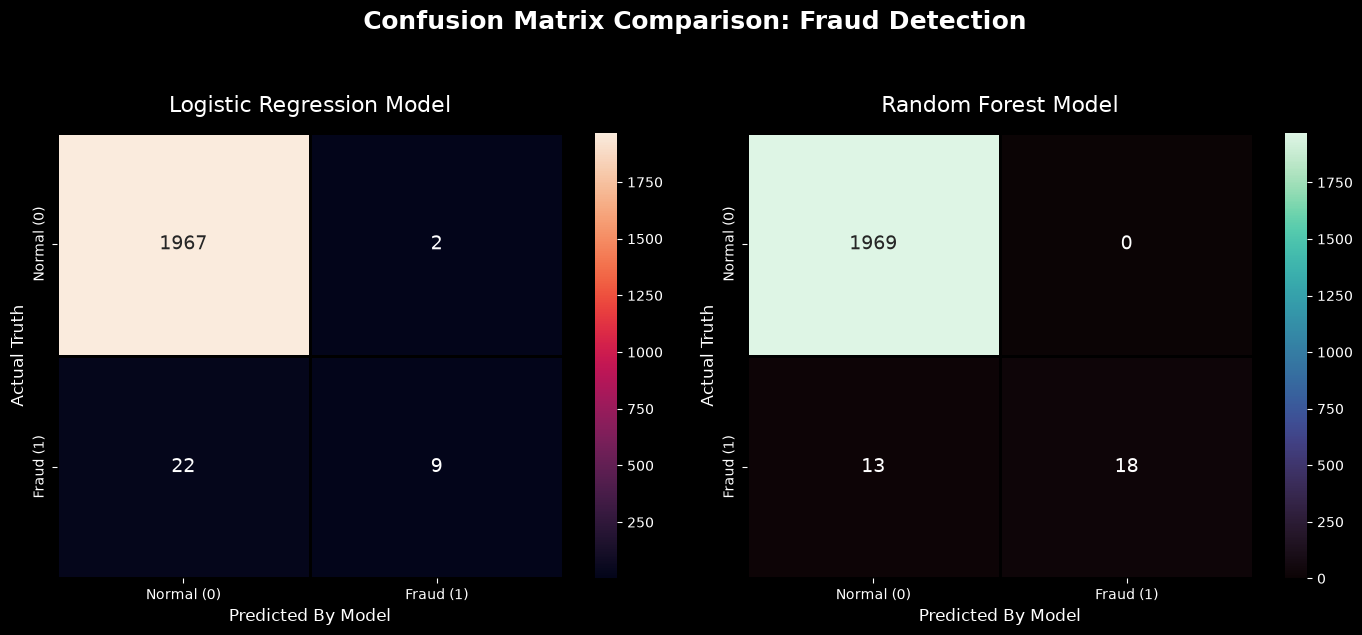

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

# 1. Loading the  data and splitting it.
df = pd.read_csv("cleaned_credit_card_fraud_10k.csv")
X = df.drop(columns=['is_fraud'])
y = df['is_fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Training the models
log_model = LogisticRegression()
log_model.fit(X_train, y_train)
log_preds = log_model.predict(X_test)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 3. Calculating the Confusion Matrices
cm_log = confusion_matrix(y_test, log_preds)
cm_rf = confusion_matrix(y_test, rf_preds)

# -- VISUALISTAION SECTION --

# Applying a dark-themed aesthetic for a professional dashboard look
plt.style.use('dark_background')

# Creating a wide canvas with two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Defining sharp color palettes that pop against the dark background
cmap_log = sns.color_palette("rocket", as_cmap=True)
cmap_rf = sns.color_palette("mako", as_cmap=True)

# Plot 1: Logistic Regression Heatmap
sns.heatmap(cm_log, annot=True, fmt='d', cmap=cmap_log, ax=axes[0], 
            xticklabels=['Normal (0)', 'Fraud (1)'], 
            yticklabels=['Normal (0)', 'Fraud (1)'],
            linewidths=1, linecolor='black', annot_kws={"size": 14})
axes[0].set_title('Logistic Regression Model', fontsize=16, pad=15)
axes[0].set_xlabel('Predicted By Model', fontsize=12)
axes[0].set_ylabel('Actual Truth', fontsize=12)

# Plot 2: Random Forest Heatmap
sns.heatmap(cm_rf, annot=True, fmt='d', cmap=cmap_rf, ax=axes[1], 
            xticklabels=['Normal (0)', 'Fraud (1)'], 
            yticklabels=['Normal (0)', 'Fraud (1)'],
            linewidths=1, linecolor='black', annot_kws={"size": 14})
axes[1].set_title('Random Forest Model', fontsize=16, pad=15)
axes[1].set_xlabel('Predicted By Model', fontsize=12)
axes[1].set_ylabel('Actual Truth', fontsize=12)

# Adding a main title to the entire image
plt.suptitle('Confusion Matrix Comparison: Fraud Detection', fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## I feel the data is a bit imbalanced So I want to handle it using SMOTE. I want to compare both the predictions.

In [18]:
%pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
  

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE

# 1. Load data
df = pd.read_csv("cleaned_credit_card_fraud_10k.csv")
X = df.drop(columns=['is_fraud'])
y = df['is_fraud']

# 2. Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train BEFORE SMOTE
log_model_before = LogisticRegression()
log_model_before.fit(X_train, y_train)
log_preds_before = log_model_before.predict(X_test)

rf_model_before = RandomForestClassifier(random_state=42)
rf_model_before.fit(X_train, y_train)
rf_preds_before = rf_model_before.predict(X_test)

# 4. Apply SMOTE to training data ONLY
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# 5. Train AFTER SMOTE
log_model_after = LogisticRegression()
log_model_after.fit(X_train_smote, y_train_smote)
log_preds_after = log_model_after.predict(X_test)

rf_model_after = RandomForestClassifier(random_state=42)
rf_model_after.fit(X_train_smote, y_train_smote)
rf_preds_after = rf_model_after.predict(X_test)

# Print reports to output
print("--- Logistic Regression (BEFORE SMOTE) ---")
print(classification_report(y_test, log_preds_before))
print("--- Logistic Regression (AFTER SMOTE) ---")
print(classification_report(y_test, log_preds_after))

print("--- Random Forest (BEFORE SMOTE) ---")
print(classification_report(y_test, rf_preds_before))
print("--- Random Forest (AFTER SMOTE) ---")
print(classification_report(y_test, rf_preds_after))

# 6. Visualization: 2x2 Confusion Matrices
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cmap_before = sns.color_palette("rocket", as_cmap=True)
cmap_after = sns.color_palette("mako", as_cmap=True)

def plot_cm(ax, y_true, y_pred, title, cmap):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['Normal (0)', 'Fraud (1)'],
                yticklabels=['Normal (0)', 'Fraud (1)'],
                linewidths=1, linecolor='black', annot_kws={"size": 14})
    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual', fontsize=10)

plot_cm(axes[0, 0], y_test, log_preds_before, 'Log Reg: BEFORE SMOTE', cmap_before)
plot_cm(axes[0, 1], y_test, log_preds_after, 'Log Reg: AFTER SMOTE', cmap_after)
plot_cm(axes[1, 0], y_test, rf_preds_before, 'Random Forest: BEFORE SMOTE', cmap_before)
plot_cm(axes[1, 1], y_test, rf_preds_after, 'Random Forest: AFTER SMOTE', cmap_after)

plt.suptitle('The Power of SMOTE: Before vs After', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('smote_comparison.png', dpi=300, bbox_inches='tight')
plt.close()

c:\Users\Rohan pais\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Rohan pais\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    htt

--- Logistic Regression (BEFORE SMOTE) ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1969
           1       0.82      0.29      0.43        31

    accuracy                           0.99      2000
   macro avg       0.90      0.64      0.71      2000
weighted avg       0.99      0.99      0.99      2000

--- Logistic Regression (AFTER SMOTE) ---
              precision    recall  f1-score   support

           0       1.00      0.94      0.97      1969
           1       0.16      0.77      0.27        31

    accuracy                           0.93      2000
   macro avg       0.58      0.86      0.62      2000
weighted avg       0.98      0.93      0.95      2000

--- Random Forest (BEFORE SMOTE) ---
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1969
           1       1.00      0.58      0.73        31

    accuracy                           0.99      2000
   mac

### The results from applying SMOTE demonstrate one of the most fundamental concepts in machine learning: the Precision-Recall Trade-off. Here is a detailed, professional insight you can include directly in your Week 2 report:

### **1. The Baseline Problem (Before SMOTE)**
### Before applying SMOTE, the Logistic Regression model was heavily biased toward the majority class (normal transactions). Out of 31 actual fraud cases, it only identified 29% (Recall = 0.29). Because fraud is so mathematically rare, the model essentially learned to predict "normal" by default. While this resulted in a deceptive 99% overall accuracy, it failed at its primary business objective: catching financial thieves.

### **2. The SMOTE Effect on Logistic Regression**
### Applying SMOTE successfully forced the model to study synthetic fraud examples, completely changing its behavior. The model's ability to catch actual fraud skyrocketed, identifying 77% of all fraudulent transactions (Recall increased from 0.29 to 0.77).
### However, this came at a severe cost. The model became overly sensitive and paranoid, causing Precision to plummet from 0.82 down to just 0.16. In a real-world banking context, a precision of 16% means that every time the model freezes a credit card for suspected fraud, the customer is actually innocent 84% of the time. This massive spike in false alarms would overwhelm a customer service department and cause intense customer frustration.

### **3. The Superiority of Tree-Based Models**
### Even without SMOTE, the Random Forest model proved to be significantly more robust against imbalanced data. It achieved a 58% Recall while maintaining a flawless 1.00 (100%) Precision. It caught double the amount of fraud compared to the baseline Logistic Regression model without making a single false accusation against a legitimate shopper.

### **Final Business Verdict:**
### While SMOTE successfully cured the Logistic Regression model's "blindness" to fraud by boosting recall, the resulting drop in precision makes it too aggressive for a real-world application. The Random Forest model remains the superior choice, as decision trees naturally handle imbalanced datasets better and provide a much safer, more profitable balance between catching fraud and protecting the customer experience.